Importación de modulos necesarios

In [1]:
import csv
import os
from collections import deque
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ultralytics import RTDETR, YOLO


**Detección con modelo YOLOv11**

Carga y configuración de los modelos para la de

**Primer paso**. Se cargarán los modelos de detección general y de matrículas, de tal forma que todo funcione correctamente a la hora del procesado del vídeo.

In [2]:
source_video = "C0142.mp4"
output_video = "output.mp4"
csv_output = "detections.csv"

# Carga de los modelos: preentrenado y detección de matrículas
general_model = YOLO("yolo11n.pt")
plate_model = YOLO("./runs/detect/yolo_runs/plates_detection/weights/best.pt")

# Definición de las clases de interés
PERSON = 0
VEHICLES = {1, 2, 3, 5}  # bicicleta, coche, moto, guagua
CLASSES = [PERSON, *VEHICLES]
PLATE_VEHICLES = {2, 3, 5}  # vehículos con matrícula

# Parámetros de detección y recorte
conf_coco = 0.4
conf_plate = 0.3
padding = 0.05  # margen extra alrededor del vehículo (5%)

# Color por clase (BGR) y color de matrícula
class_colors = {
    0: (0, 200, 0),  # persona
    1: (200, 0, 200),  # bicicleta
    2: (255, 120, 0),  # coche
    3: (0, 165, 255),  # moto
    5: (0, 200, 255),  # guagua
}
plate_color = (0, 0, 255)

# Nombres para mostrar en pantalla
display_names = {0: "Persona", 1: "Bicicleta", 2: "Coche", 3: "Moto", 5: "Guagua"}

face_ratio = 0.22  # se asume que la fracción superior de la caja es la cara

# Parámetros del flujo
margin = 0.08
min_history = 5
lost_frames = 15
directions = ["izquierda", "derecha"]

Posteriormente, se procederá al entrenamiento del modelo haciendo uso de un dataset y alguno de los presentes comandos desde Anaconda Prompt:

IMPORTANTE: Previamente el usuario deberá haber establecido el directorio actual como P4. En caso contrario, se deberá de escribir la ruta completa.

- Si el sistema dispone de GPU compatible con CUDA: yolo detect train data=data.yaml model=yolo11n.pt imgsz=416 batch=4 device=0 epochs=40 project=yolo_runs name=plates_detection exist_ok=True hsv_h=0.015 hsv_s=0.5 hsv_v=0.3 degrees=5 translate=0.1 scale=0.3 fliplr=0.0 mosaic=0.5

- Si el sistema no es compatible con CUDA, se usará CPU: yolo detect train data=data.yaml model=yolo11n.pt imgsz=416 batch=4 device=cpu epochs=40 project=yolo_runs name=plates_detection exist_ok=True hsv_h=0.015 hsv_s=0.5 hsv_v=0.3 degrees=5 translate=0.1 scale=0.3 fliplr=0.0 mosaic=0.5


**Segundo paso**. Se definirán funciones auxiliares para extraer la información y generar el archivo CSV.

In [3]:
def write_csv_header(path):
    with open(path, "w", newline="", encoding="utf-8") as f:
        csv.writer(f).writerow(
            [
                "fotograma",
                "tipo_objeto",
                "confianza",
                "identificador_tracking",
                "x1",
                "y1",
                "x2",
                "y2",
                "matricula_en_su_caso",
                "confianza_matricula",
                "mx1",
                "my1",
                "mx2",
                "my2",
                "texto_matricula",
            ]
        )


def make_row(frame_n, name, conf, tid, box, plate=None):
    """plate: None o (pconf, mx1, my1, mx2, my2)."""
    x1, y1, x2, y2 = box
    if plate is not None:
        pconf, mx1, my1, mx2, my2 = plate
        plate_part = ["Si", f"{pconf:.3f}", mx1, my1, mx2, my2, ""]
    else:
        plate_part = ["No", "", "", "", "", "", ""]
    return [
        frame_n,
        name,
        f"{conf:.3f}",
        tid if tid is not None else "",
        x1,
        y1,
        x2,
        y2,
        *plate_part,
    ]


def append_rows(path, rows):
    with open(path, "a", newline="", encoding="utf-8") as f:
        csv.writer(f).writerows(rows)

**Tercer paso** Se configuran los parámetros para la obtención del vídeo y se inicializan el archivo CSV y el cálculo del flujo de detecciones.

In [4]:
vid = cv2.VideoCapture(source_video)
fps = vid.get(cv2.CAP_PROP_FPS)
w = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))
out = cv2.VideoWriter(output_video, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

write_csv_header(csv_output)

unique_ids = {c: set() for c in CLASSES}
track_class = {}
plate_ids = set()

track_history = {}
last_seen = {}
counted_exit = set()
exit_count = {d: {c: 0 for c in CLASSES} for d in directions}

**Cuarto paso**. Asimismo, se definirán funciones auxiliares para el dibujado de las detecciones, el anonimizado de las mismas y el cálculo del flujo.

In [5]:
def draw(frame, box, label, color):
    x1, y1, x2, y2 = map(int, box)
    cv2.rectangle(frame, (x1, y1), (x2, y2), color, 2)
    (tw, th), _ = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, 0.5, 1)
    cv2.rectangle(frame, (x1, y1 - th - 6), (x1 + tw + 4, y1), color, -1)
    cv2.putText(
        frame,
        label,
        (x1 + 2, y1 - 4),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 255, 255),
        1,
    )


def pixelate(frame, box, factor=10):
    x1, y1, x2, y2 = map(int, box)
    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)
    roi = frame[y1:y2, x1:x2]
    if roi.size == 0:
        return
    rh, rw = roi.shape[:2]
    small = cv2.resize(
        roi,
        (max(1, rw // factor), max(1, rh // factor)),
        interpolation=cv2.INTER_LINEAR,
    )
    frame[y1:y2, x1:x2] = cv2.resize(small, (rw, rh), interpolation=cv2.INTER_NEAREST)


def exit_direction(cx, cy):
    """Borde por el que sale el objeto, o None si no está cerca de ninguno."""
    if cx <= w * margin:
        return "izquierda"
    if cx >= w * (1 - margin):
        return "derecha"
    return None


def update_exits(current_frame):
    """Cuenta como salida los IDs que llevan más de lost_frames sin verse."""
    for tid in [t for t, f in last_seen.items() if current_frame - f > lost_frames]:
        hist = track_history.pop(tid)
        del last_seen[tid]
        if len(hist) >= min_history and tid not in counted_exit:
            d = exit_direction(*hist[-1])
            if d:
                exit_count[d][track_class[tid]] += 1
                counted_exit.add(tid)


flow_color = (0, 255, 255)
arrows = {"izquierda": "<-", "derecha": "->"}


def draw_panel(frame, x, y, title, lines, color, width=190):
    """Panel con fondo oscuro semitransparente, título y líneas de texto."""
    lh = 22
    height = 30 + lh * len(lines)
    overlay = frame.copy()
    cv2.rectangle(overlay, (x, y), (x + width, y + height), (30, 30, 30), -1)
    cv2.addWeighted(overlay, 0.6, frame, 0.4, 0, frame)
    cv2.rectangle(frame, (x, y), (x + width, y + height), color, 1)
    cv2.putText(
        frame,
        title,
        (x + 8, y + 20),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.6,
        color,
        2,
        cv2.LINE_AA,
    )
    for i, txt in enumerate(lines):
        cv2.putText(
            frame,
            txt,
            (x + 8, y + 20 + lh * (i + 1)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            (255, 255, 255),
            1,
            cv2.LINE_AA,
        )


def render(frame, draws, count_lines, flow_lines):
    for box, label, color in draws:
        draw(frame, box, label, color)
    draw_panel(frame, 10, 10, "DETECCIONES", count_lines, (255, 255, 255))
    y_flow = 10 + 30 + 22 * len(count_lines) + 10
    draw_panel(frame, 10, y_flow, "FLUJO (salidas)", flow_lines, flow_color)

**Quinto paso**. Inicializadas y configuradas todas las dependencias necesarias, se procederá al procesado del vídeo de test con el presente bucle: se analizarán los fotogramas y se realizarán los cálculos y guardados pernitentes según lo estipulado en el guión práctico (cálculo del flujo, generación de archivo CSV...).

In [7]:
frame_n = 0
while True:
    ret, frame = vid.read()
    if not ret:
        break
    frame_n += 1

    r = general_model.track(
        frame, persist=True, classes=CLASSES, conf=conf_coco, verbose=True
    )[0]
    ids = (
        r.boxes.id.cpu().numpy().astype(int)
        if r.boxes.id is not None
        else [None] * len(r.boxes)
    )

    rows, draws, anon_boxes = [], [], []
    for box, cls, conf, tid in zip(
        r.boxes.xyxy.cpu().numpy(),
        r.boxes.cls.cpu().numpy().astype(int),
        r.boxes.conf.cpu().numpy(),
        ids,
    ):
        x1, y1, x2, y2 = map(int, box)

        if tid is not None:
            cls = track_class.setdefault(tid, cls)
            unique_ids[cls].add(tid)
            track_history.setdefault(tid, deque(maxlen=30)).append(
                ((x1 + x2) // 2, (y1 + y2) // 2)
            )
            last_seen[tid] = frame_n

        name = general_model.names[cls]
        tag = f"{name} #{tid}" if tid is not None else name
        draws.append((box, f"{tag} {conf:.2f}", class_colors[cls]))

        if cls == PERSON:
            anon_boxes.append((x1, y1, x2, y1 + int((y2 - y1) * face_ratio)))

        plate = None
        if cls in PLATE_VEHICLES:
            bw, bh = x2 - x1, y2 - y1
            cx1 = max(0, int(x1 - bw * padding))
            cy1 = max(0, int(y1 - bh * padding))
            cx2 = min(w, int(x2 + bw * padding))
            cy2 = min(h, int(y2 + bh * padding))
            crop = frame[cy1:cy2, cx1:cx2]
            if crop.size:
                res = plate_model.predict(crop, conf=conf_plate, verbose=True)[0]
                if len(res.boxes):
                    i = int(res.boxes.conf.argmax())
                    pconf = float(res.boxes.conf[i])
                    px1, py1, px2, py2 = res.boxes.xyxy[i].cpu().numpy()
                    plate = (
                        pconf,
                        int(px1 + cx1),
                        int(py1 + cy1),
                        int(px2 + cx1),
                        int(py2 + cy1),
                    )
                    draws.append((plate[1:], f"plate {pconf:.2f}", plate_color))
                    anon_boxes.append(plate[1:])
                    if tid is not None:
                        plate_ids.add(tid)

        rows.append(make_row(frame_n, name, conf, tid, (x1, y1, x2, y2), plate))

    append_rows(csv_output, rows)
    update_exits(frame_n)

    count_lines = [f"{display_names[c]}: {len(unique_ids[c])}" for c in CLASSES]
    count_lines.append(f"matricula: {len(plate_ids)}")
    flow_lines = [f"{arrows[d]} {d}: {sum(exit_count[d].values())}" for d in directions]

    for b in anon_boxes:
        pixelate(frame, b)
    render(frame, draws, count_lines, flow_lines)
    out.write(frame)

update_exits(frame_n + lost_frames + 1)

vid.release()
out.release()
print("Vídeo con las detecciones generado:", output_video)
print("CSV con las detecciones generado:", csv_output)


0: 384x640 1 car, 1 bus, 10.6ms
Speed: 1.5ms preprocess, 10.6ms inference, 1.4ms postprocess per image at shape (1, 3, 384, 640)

0: 352x416 1 plate, 7.5ms
Speed: 0.6ms preprocess, 7.5ms inference, 1.0ms postprocess per image at shape (1, 3, 352, 416)

0: 416x416 (no detections), 11.7ms
Speed: 0.8ms preprocess, 11.7ms inference, 0.5ms postprocess per image at shape (1, 3, 416, 416)

0: 384x640 1 car, 1 bus, 11.1ms
Speed: 1.3ms preprocess, 11.1ms inference, 1.5ms postprocess per image at shape (1, 3, 384, 640)

0: 352x416 1 plate, 11.0ms
Speed: 0.8ms preprocess, 11.0ms inference, 1.0ms postprocess per image at shape (1, 3, 352, 416)

0: 416x384 (no detections), 9.9ms
Speed: 0.7ms preprocess, 9.9ms inference, 0.4ms postprocess per image at shape (1, 3, 416, 384)

0: 384x640 1 car, 1 bus, 9.2ms
Speed: 1.4ms preprocess, 9.2ms inference, 1.2ms postprocess per image at shape (1, 3, 384, 640)

0: 352x416 1 plate, 9.1ms
Speed: 0.8ms preprocess, 9.1ms inference, 1.5ms postprocess per image at 

**Detección con modelo RT-DETR**

Con el fin de realizar un proceso de detección de matrículas análogo al realizado con yolo, se procederá a entrenar un modelo RT-DETR para la detección de las mismas.

Para ello se volverá a hacer uso de Anaconda Prompt y de alguno de los siguientes comandos:

- Si el sistema dispone de GPU compatible con CUDA: yolo detect train data=data.yaml model=rtdetr-l.pt imgsz=416 batch=4 device=0 epochs=40 project=rtdetr_runs name=plates_detection exist_ok=True hsv_h=0.015 hsv_s=0.5 hsv_v=0.3 degrees=5 translate=0.1 scale=0.3 fliplr=0.0 mosaic=0.5

- Si el sistema no es compatible con CUDA, se usará CPU: yolo detect train data=data.yaml model=rtdetr-l.pt imgsz=416 batch=4 device=cpu epochs=40 project=rtdetr_runs name=plates_detection exist_ok=True hsv_h=0.015 hsv_s=0.5 hsv_v=0.3 degrees=5 translate=0.1 scale=0.3 fliplr=0.0 mosaic=0.5

Alternativamente, se podría realizar el entrenamiento de RT-DETR ejecutándolo como comando desde una celda

Métricas de validación del modelo RT-DETR.

In [12]:
data_yaml = "./data.yaml"
rtdetr_plate_path = "./runs/detect/rtdetr_runs/plates_detection/weights/best.pt"

rtdetr_metrics = RTDETR(rtdetr_plate_path).val(data=data_yaml, imgsz=640, verbose=False)
print(
    f"precision: {rtdetr_metrics.box.mp:.3f}  recall: {rtdetr_metrics.box.mr:.3f}"
    f"mAP50: {rtdetr_metrics.box.map50:.3f} mAP50-95: {rtdetr_metrics.box.map:.3f}"
)

Ultralytics 8.4.198  Python-3.9.25 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8124MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access  (ping: 0.3±0.1 ms, read: 409.6±647.8 MB/s, size: 481.6 KB)
val: Scanning C:\Users\nedeg\Desktop\Prácticas_VC\Practicas_VC_2026-2027\P4\VC_Plates_dataset\val\labels.cache... 43 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 43/43  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.3s/it 3.8s1.1s3s
                   all         43         50      0.842       0.94      0.918      0.695
Speed: 1.9ms preprocess, 35.3ms inference, 0.0ms loss, 0.2ms postprocess per image
Results saved to C:\Users\nedeg\Desktop\Prácticas_VC\Practicas_VC_2026-2027\P4\runs\detect\val
precision: 0.842  recall: 0.940mAP50: 0.918 mAP50-95: 0.695


De manera análoga a como se realizó con YOLO, se procederá a la carga de modelos y preparación del vídeo, inicializando nuevamente contadores para obtener un resultado en la ejecución que no acumule cálculos de la realizada con YOLO.

In [13]:
output_video_rtdetr = "output_rtdetr.mp4"
csv_output_rtdetr = "detections_rtdetr.csv"

# Detector general nuevo (para que el tracker empiece desde cero) y modelo de matrículas RT-DETR
general_model = YOLO("yolo11n.pt")
rtdetr_plate_model = RTDETR(rtdetr_plate_path)

vid = cv2.VideoCapture(source_video)
fps = vid.get(cv2.CAP_PROP_FPS)
w = int(vid.get(cv2.CAP_PROP_FRAME_WIDTH))
h = int(vid.get(cv2.CAP_PROP_FRAME_HEIGHT))
out = cv2.VideoWriter(output_video_rtdetr, cv2.VideoWriter_fourcc(*"mp4v"), fps, (w, h))

write_csv_header(csv_output_rtdetr)

unique_ids = {c: set() for c in CLASSES}
track_class = {}
plate_ids = set()

track_history = {}
last_seen = {}
counted_exit = set()
exit_count = {d: {c: 0 for c in CLASSES} for d in directions}

De igual manera que para YOLO, se procesará el video en un bucle. Para este escenario se ha prescindido de algunas características del bucle anterior, reutilizando únicamente aquellas consideradas primordiales para la comparación: detección y seguimiento de personas y vehículos, detección de matrículas, conteo y generación de video y archivo CSV.

Debido a como se trata la detección de matrículas en el bucle de ejecución de YOLO, se ha optado por seguir haciendo uso como modelo general la red YOLOv11. Esto se debe a que, como la zona de búsqueda de matrículas se acota a aquellas detecciones consideradas vehículos, se ha determinado que la situación más justa es que se tome como base las mismas detecciones iniciales que se detectan en el bucle de YOLO, únicamente cambiando el modelo de detección de matrículas.

In [14]:
frame_n = 0
while True:
    ret, frame = vid.read()
    if not ret:
        break
    frame_n += 1

    r = general_model.track(frame, persist=True, classes=CLASSES, conf=conf_coco, verbose=False)[0]
    ids = (r.boxes.id.cpu().numpy().astype(int) if r.boxes.id is not None else [None] * len(r.boxes))

    rows, draws, anon_boxes = [], [], []
    for box, cls, conf, tid in zip(
        r.boxes.xyxy.cpu().numpy(),
        r.boxes.cls.cpu().numpy().astype(int),
        r.boxes.conf.cpu().numpy(),
        ids,
    ):
        x1, y1, x2, y2 = map(int, box)

        if tid is not None:
            cls = track_class.setdefault(tid, cls)
            unique_ids[cls].add(tid)
            track_history.setdefault(tid, deque(maxlen=30)).append(
                ((x1 + x2) // 2, (y1 + y2) // 2)
            )
            last_seen[tid] = frame_n

        name = general_model.names[cls]
        tag = f"{name} #{tid}" if tid is not None else name
        draws.append((box, f"{tag} {conf:.2f}", class_colors[cls]))

        # Matrícula: se detecta sobre el recorte del vehículo (con margen)
        plate = None
        if cls in PLATE_VEHICLES:
            bw, bh = x2 - x1, y2 - y1
            cx1 = max(0, int(x1 - bw * padding))
            cy1 = max(0, int(y1 - bh * padding))
            cx2 = min(w, int(x2 + bw * padding))
            cy2 = min(h, int(y2 + bh * padding))
            crop = frame[cy1:cy2, cx1:cx2]

            if crop.size:
                res = rtdetr_plate_model.predict(crop, conf=conf_plate, verbose=False)[0]
                if len(res.boxes):
                    i = int(res.boxes.conf.argmax())
                    pconf = float(res.boxes.conf[i])
                    px1, py1, px2, py2 = res.boxes.xyxy[i].cpu().numpy()
                    plate = (
                        pconf,
                        int(px1 + cx1),
                        int(py1 + cy1),
                        int(px2 + cx1),
                        int(py2 + cy1),
                    )
                    draws.append((plate[1:], f"plate {pconf:.2f}", plate_color))
                    if tid is not None:
                        plate_ids.add(tid)

        rows.append(make_row(frame_n, name, conf, tid, (x1, y1, x2, y2), plate))

    append_rows(csv_output_rtdetr, rows)
    update_exits(frame_n)

    for box, label, color in draws:
        draw(frame, box, label, color)
    count_lines = [f"{display_names[c]}: {len(unique_ids[c])}" for c in CLASSES]
    count_lines.append(f"Matrícula: {len(plate_ids)}")
    draw_panel(frame, 10, 10, "DETECCIONES", count_lines, (255, 255, 255))
    out.write(frame)

vid.release()
out.release()
print("Vídeo con las detecciones generado:", output_video_rtdetr)
print("CSV con las detecciones generado:", csv_output_rtdetr)

Vídeo con las detecciones generado: output_rtdetr.mp4
CSV con las detecciones generado: detections_rtdetr.csv


Total de cada clase (identificadores únicos)

In [15]:
for c in CLASSES:
    print(f"{display_names[c]}: {len(unique_ids[c])}")
print(f"Vehículos con matrícula detectada: {len(plate_ids)}")

Persona: 16
Bicicleta: 1
Coche: 40
Moto: 1
Guagua: 1
Vehículos con matrícula detectada: 31


Comparativa entre ambos modelos

Para el mismo data.yaml y mismo imgsz para ambos modelos.

In [16]:
yolo_plate_path = "./runs/detect/yolo_runs/plates_detection/weights/best.pt"


def validate(model, name):
    v = model.val(data=data_yaml, imgsz=640, plots=False, verbose=False)
    p, r = float(v.box.mp), float(v.box.mr)
    return {
        "modelo": name,
        "precision": p,
        "recall": r,
        "F1": 2 * p * r / (p + r) if (p + r) else 0.0,
        "mAP50": float(v.box.map50),
        "mAP50-95": float(v.box.map),
        "inferencia_ms/img": v.speed["inference"],
    }


val_df = pd.DataFrame(
    [
        validate(YOLO(yolo_plate_path), "YOLO"),
        validate(RTDETR(rtdetr_plate_path), "RT-DETR"),
    ]
).set_index("modelo")
val_df.round(4)

Ultralytics 8.4.198  Python-3.9.25 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8124MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1597.4±1448.2 MB/s, size: 659.7 KB)
val: Scanning C:\Users\nedeg\Desktop\Prácticas_VC\Practicas_VC_2026-2027\P4\VC_Plates_dataset\val\labels.cache... 43 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 43/43  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 1.2it/s 2.5s0.7ss
                   all         43         50      0.921      0.929      0.946      0.654
Speed: 0.9ms preprocess, 8.6ms inference, 0.0ms loss, 1.4ms postprocess per image
Ultralytics 8.4.198  Python-3.9.25 torch-2.8.0+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Laptop GPU, 8124MiB)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access  (ping: 0.1±0.0 ms, read: 1

,precision,recall,F1,mAP50,mAP50-95,inferencia_ms/img
modelo,,,,,,
YOLO,0.9207,0.9292,0.9249,0.9456,0.6538,8.5778
RT-DETR,0.8416,0.9400,0.8881,0.9184,0.6948,18.9669


- mAP50 y mAP50-95 son las métricas estándar. mAP50-95 penaliza más las cajas poco ajustadas.
- Precisión, recall y F1, que dan la lectura práctica: matrículas que se escapan frente a falsos positivos.

Curvas de entrenamiento (a partir del results.csv de cada entrenamiento). Las curvas PR, F1 y la matriz de confusión ya las guarda Ultralytics en la carpeta de cada entrenamiento.

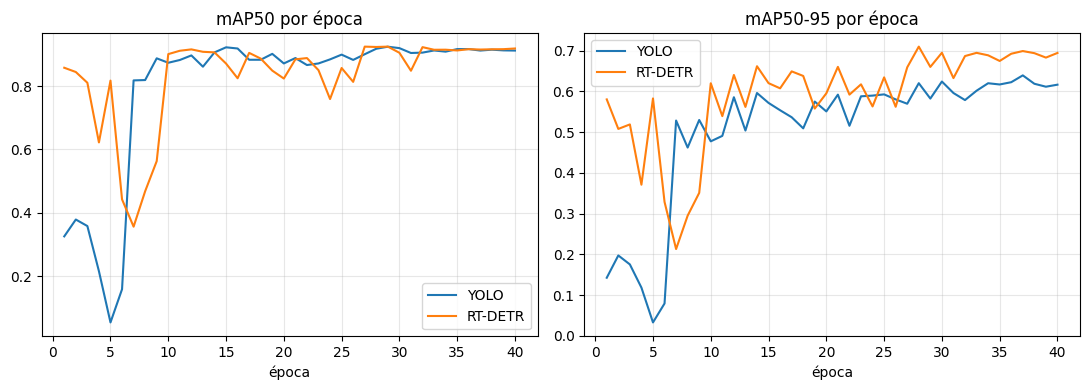

In [17]:
def load_results(weights_path):
    df = pd.read_csv(Path(weights_path).parent.parent / "results.csv")
    df.columns = df.columns.str.strip()
    return df


res = {
    "YOLO": load_results(yolo_plate_path),
    "RT-DETR": load_results(rtdetr_plate_path),
}
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

for name, df in res.items():
    ax[0].plot(df["epoch"], df["metrics/mAP50(B)"], label=name)
    ax[1].plot(df["epoch"], df["metrics/mAP50-95(B)"], label=name)
ax[0].set_title("mAP50 por época")
ax[1].set_title("mAP50-95 por época")

for a in ax:
    a.set_xlabel("época")
    a.legend()
    a.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Resultados sobre el vídeo a partir de los CSV generados (detections.csv para YOLO y detections_rtdetr.csv para RT-DETR). Sin anotaciones del vídeo, son indicadores de comportamiento, no de precisión real.

In [18]:
PLATE_TYPES = {"car", "motorcycle", "bus"}
MIN_FRAMES = 5


def load_det(path):
    df = pd.read_csv(path)
    df = df[df["tipo_objeto"].isin(PLATE_TYPES)].copy()
    df["tiene_matricula"] = df["matricula_en_su_caso"] == "Si"
    return df


det = {"YOLO": load_det(csv_output), "RT-DETR": load_det(csv_output_rtdetr)}


def video_metrics(df):
    tracked = df.dropna(subset=["identificador_tracking"]).copy()
    tracked["identificador_tracking"] = tracked["identificador_tracking"].astype(int)
    per_id = tracked.sort_values("fotograma").groupby("identificador_tracking")["tiene_matricula"]
    n_ids = per_id.ngroups
    ids_con_matricula = int(per_id.any().sum())

    # Estabilidad temporal: fracción de fotogramas con matrícula y "parpadeos" (Si -> No)
    frac, flicker = [], []
    for _, s in per_id:
        seq = s.to_numpy()
        if len(seq) < MIN_FRAMES:
            continue
        frac.append(seq.mean())
        flicker.append(int(np.sum(seq[:-1] & ~seq[-1])))

    return {
        "detecciones_vehiculo": len(df),
        "matriculas_detectadas": int(df["tiene_matricula"].sum()),
        "tasa_deteccion_matricula": df["tiene_matricula"].mean(),
        "conf_media_matricula": df.loc[
            df["tiene_matricula"], "confianza_matricula"
        ].mean(),
        "vehiculos_unicos": n_ids,
        "vehiculos_con_matricula": ids_con_matricula,
        "pct_vehiculos_con_matricula": ids_con_matricula / n_ids if n_ids else np.nan,
        "estabilidad_media (frac. frames con matricula)": float(np.mean(frac))
        if frac
        else np.nan,
        "parpadeos_medios_por_vehiculo": float(np.mean(flicker)) if flicker else np.nan,
    }


video_df = pd.DataFrame({name: video_metrics(df) for name, df in det.items()})
video_df.round(4)

,YOLO,RT-DETR
detecciones_vehiculo,6395.0000,6397.0000
matriculas_detectadas,1149.0000,1023.0000
tasa_deteccion_matricula,0.1797,0.1599
conf_media_matricula,0.7170,0.7701
vehiculos_unicos,42.0000,42.0000
vehiculos_con_matricula,28.0000,31.0000
pct_vehiculos_con_matricula,0.6667,0.7381
estabilidad_media (frac. frames con matricula),0.1965,0.1642
parpadeos_medios_por_vehiculo,27.3571,17.6905


Acuerdo entre ambos modelos por vehículo y fotograma. Como el detector y el tracker general son los mismos en las dos ejecuciones, las detecciones de vehículos coinciden y se pueden cruzar por fotograma + identificador_tracking.

In [20]:
key = ["fotograma", "identificador_tracking"]
a = det["YOLO"].dropna(subset=["identificador_tracking"])
b = det["RT-DETR"].dropna(subset=["identificador_tracking"])
m = a.merge(b, on=key, suffixes=("_yolo", "_rtdetr"))

print(f"Detecciones de vehículo cruzadas: {len(m)} (YOLO: {len(a)}, RT-DETR: {len(b)})")
agree = pd.crosstab(
    m["tiene_matricula_yolo"].map({True: "Si", False: "No"}),
    m["tiene_matricula_rtdetr"].map({True: "Si", False: "No"}),
    rownames=["YOLO"],
    colnames=["RT-DETR"],
)
display(agree)


def iou_row(r):
    iw = max(0, min(r.mx2_yolo, r.mx2_rtdetr) - max(r.mx1_yolo, r.mx1_rtdetr))
    ih = max(0, min(r.my2_yolo, r.my2_rtdetr) - max(r.my1_yolo, r.my1_rtdetr))
    inter = iw * ih
    union = (
        (r.mx2_yolo - r.mx1_yolo) * (r.my2_yolo - r.my1_yolo)      # <- aquí estaba r.mx1.yolo
        + (r.mx2_rtdetr - r.mx1_rtdetr) * (r.my2_rtdetr - r.my1_rtdetr)
        - inter
    )
    return inter / union if union > 0 else 0.0

both = m[m["tiene_matricula_yolo"] & m["tiene_matricula_rtdetr"]]
if len(both):
    print(f"IoU medio entre cajas de matrículas (ambos detectan): {both.apply(iou_row, axis=1).mean():.3f} (n={len(both)})")


Detecciones de vehículo cruzadas: 4702 (YOLO: 6393, RT-DETR: 6395)


RT-DETR,No,Si
YOLO,,
No,3392,396
Si,757,157


IoU medio entre cajas de matrículas (ambos detectan): 0.212 (n=157)


Resumen

In [21]:
summary = pd.concat([val_df.T, video_df], axis=0)
summary.round(4)

,YOLO,RT-DETR
precision,0.9207,0.8416
recall,0.9292,0.9400
F1,0.9249,0.8881
mAP50,0.9456,0.9184
mAP50-95,0.6538,0.6948
inferencia_ms/img,8.5778,18.9669
detecciones_vehiculo,6395.0000,6397.0000
matriculas_detectadas,1149.0000,1023.0000
tasa_deteccion_matricula,0.1797,0.1599
conf_media_matricula,0.7170,0.7701
